# Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import generate_large_ring as glr
import utils

# What's Available?
The Rothamsted Rsearch Centerwas scanner using LIDAR and a UAV
This resulted in a very dense single dataset that can be found on FIGSHARE: https://figshare.com/s/33033e7c6b4cad12e301 -> Full Site Dense Point Cloud.zip
This file is associated to two textures files.

The full site was split into 5 smaller maps, each associated to a single texture file (probably higher resolution then). These smaller models can be found on the same figshare.

All these files are very dense and we can not render view using the antworld rendering program.


There exist a second repository, where the 5 small models were downsampled to a manageable size, its on the Brains on Board (BoB) github: https://github.com/BrainsOnBoard/rothamsted_reconstruction/tree/master/flights 

However, its seems hat for some reason (see below) these models are tilted and, do not properly overlap anymore.
1km².

### From FIGSHARE:
- **Denser Models**: 10x denser than Lig from BoBht Models.
- **Small Maps**: Same 1km² size, but denser.
- **VERY Large Model**: Spans the area of all 5 smaller models. Needs to be 

### From Brains On Board GitHub:
- **Tilted for some reason, There's a mismatch in height when trying to merge the small maps.**
- **Light Models**: Around 500,000 vertices each.
- **Small Maps**: 1km².

## The goal of this notebook is:
 - First visualize the maps in the figshare and BoB github.
 - Then proceed to downsample the large and dense model from the Figgshare.
 - Then stitch it to a large 100 square kilometers ring map to prevent the horizon from disappearing.d small maps.


# Understanding the Brains On Board maps
# Downloading the .obj files from the figshare or Brain on Board github is required to run this notebook
## Retrieve the vertices of all models (BoB)

# Solution 1: add a large surrounding surface to prevent seeing the end of the world 
## Get 10*10 kilometers grid of altitude data

### Gaussian Sampling

In [3]:
easting, northing = 512103, 213574  # Near Rothamsted farm, roughly the centroid of the dataset
# Get the GPS coordinate on google maps and convert for reproduction
origin = (512103, 213574) # Near Rothamsted farm, roughly the centroid of the dataset

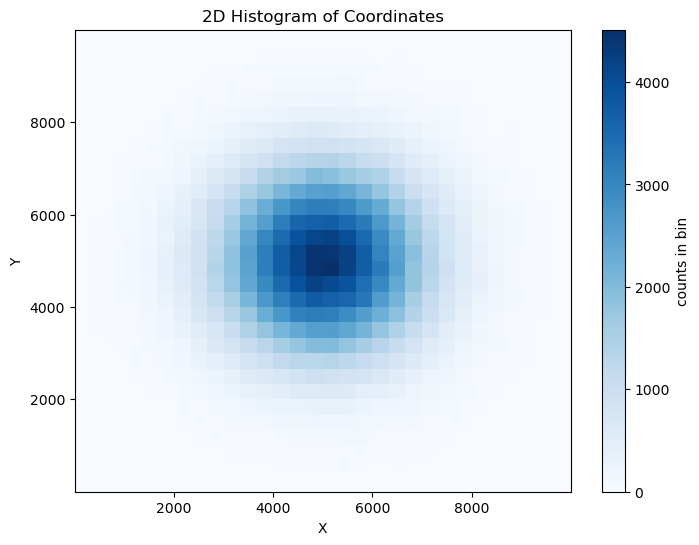

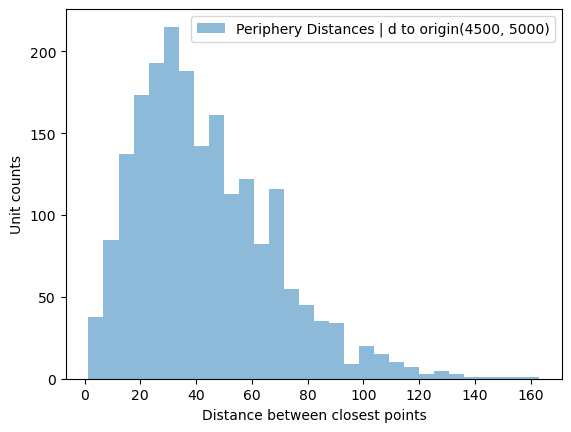

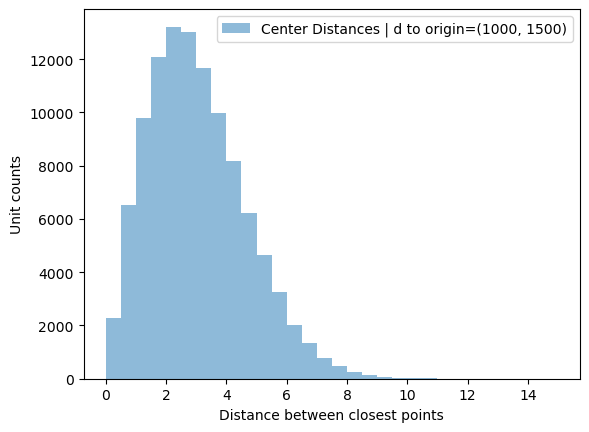

Maximum distance between points at the periphery: 163.13646674523218
Average distance between points at the periphery: 43.271798463621536
Maximum distance between points at the center: 14.966054448877081
Average distance between points at the center: 3.050888677545317
Total number of datapoints inside the borders: 499652
Coords mean -0.3670896280281463


In [5]:
size = 5000 # in meters (radius of the gaussian sampling, coordinates outside of the radius are removed
# Sample and filter coordinates
center = (size, size)
scale = 1400
matrix_size = (size*2, size*2)
n=500000
coords, tree = glr.sample_and_filter_coordinates(n=n, center=center, matrix_size=matrix_size, scale=scale)

# Classify and analyze distances
periphery_bounds=(size-500, size)
center_bounds=(1000, 1500)
glr.classify_and_analyze_distances(coords, center=center,  periphery_bounds=periphery_bounds, center_bounds=center_bounds)

coords = coords-size
print("Coords mean", coords.mean())

## Stitching agricultural altitude tiles

In [6]:
# Replace 'your_directory_path' with the path to your directory containing subdirectories with .gpkg files
directory_path = 'agricultural_tiles'
coordinates_list, tiles_list = glr.process_gpkg_files(directory_path)

PROJ: proj_create_from_database: Cannot find proj.db


agricultural_tiles\lidar_composite_dtm-2022-1-TL00ne\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL01ne\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL01se\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL10ne\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL10nw\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL11ne\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL11nw\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL11se\*.gpkg
agricultural_tiles\lidar_composite_dtm-2022-1-TL11sw\*.gpkg


### Each tile need to be reversed in the Y axis, as can be seen below

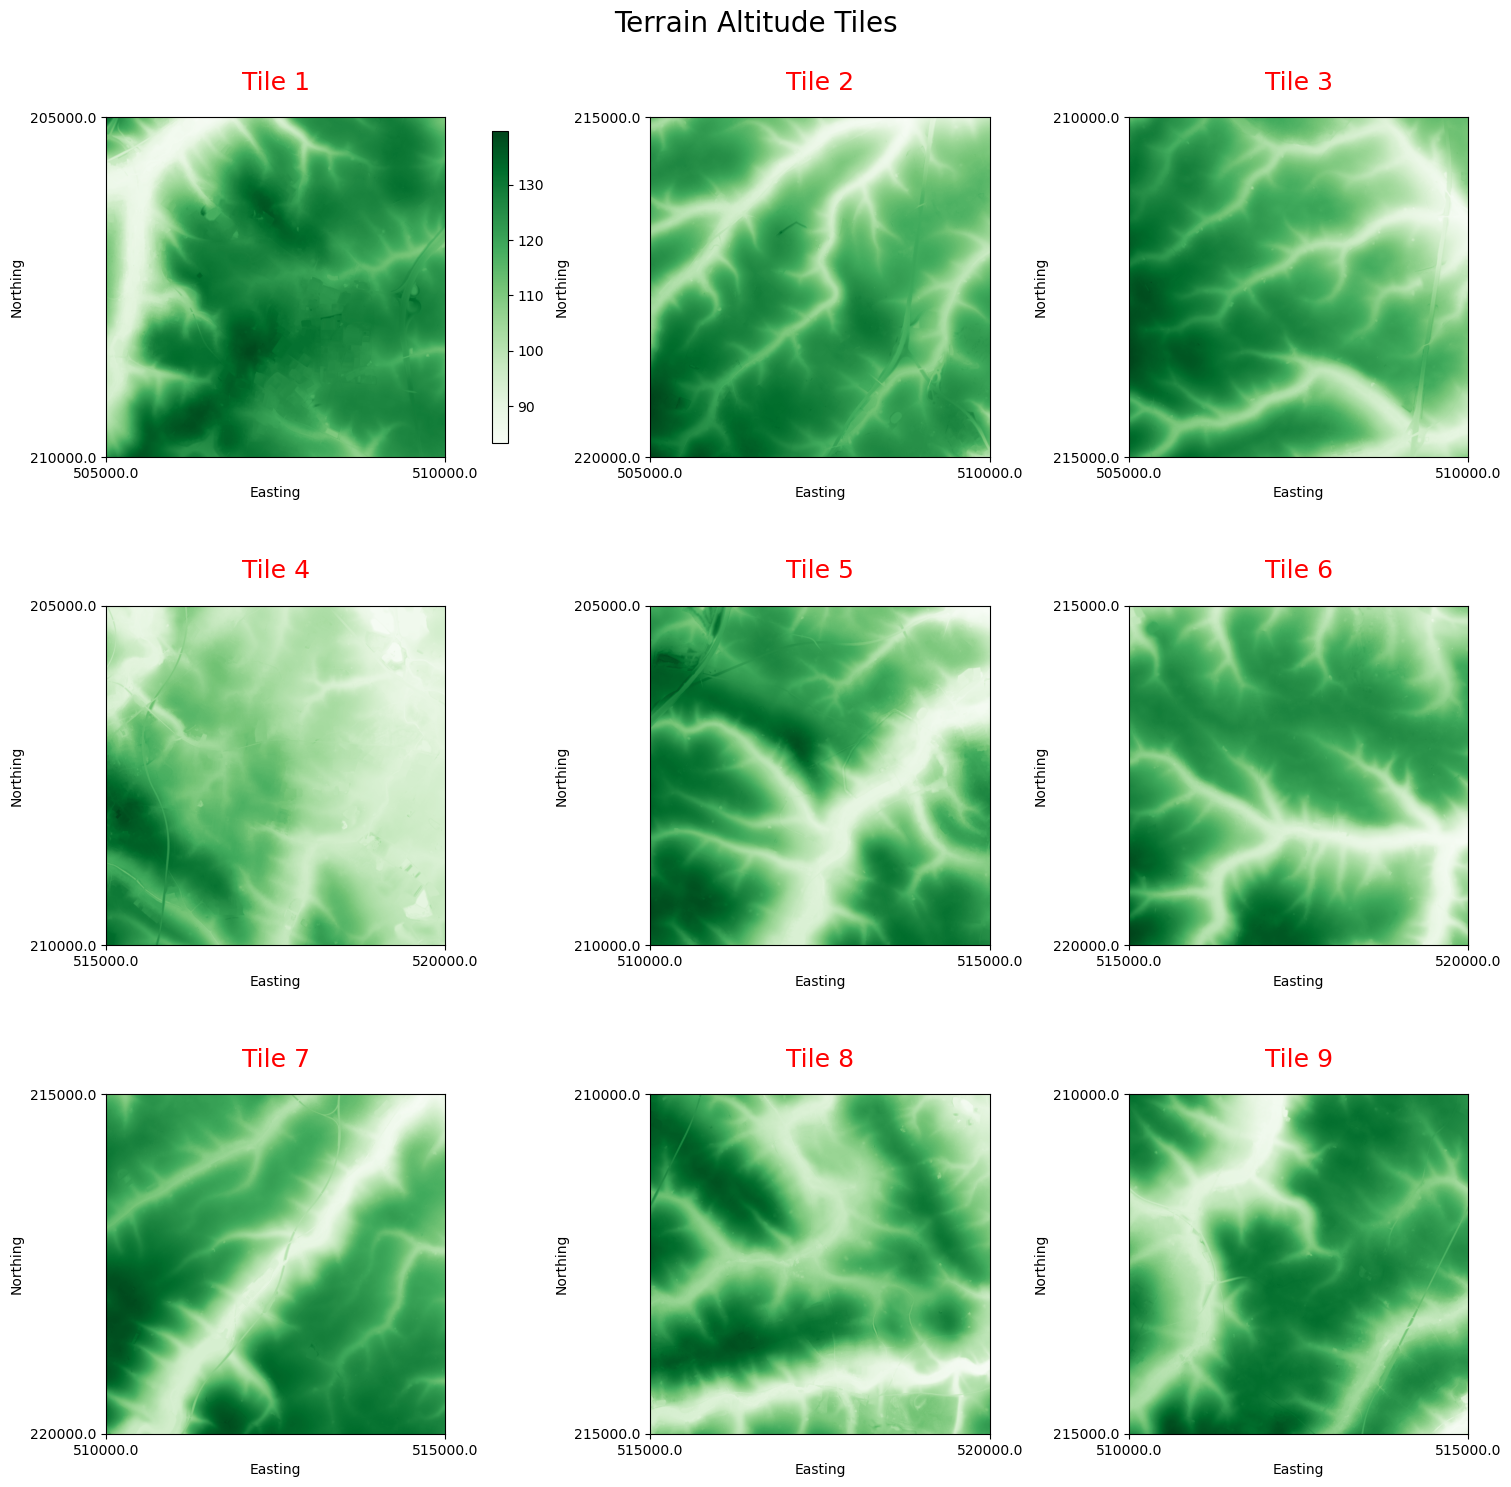

In [7]:
# Example usage, assuming coordinates_list and tiles_list are defined
glr.display_tiles_with_coordinates(coordinates_list, tiles_list)

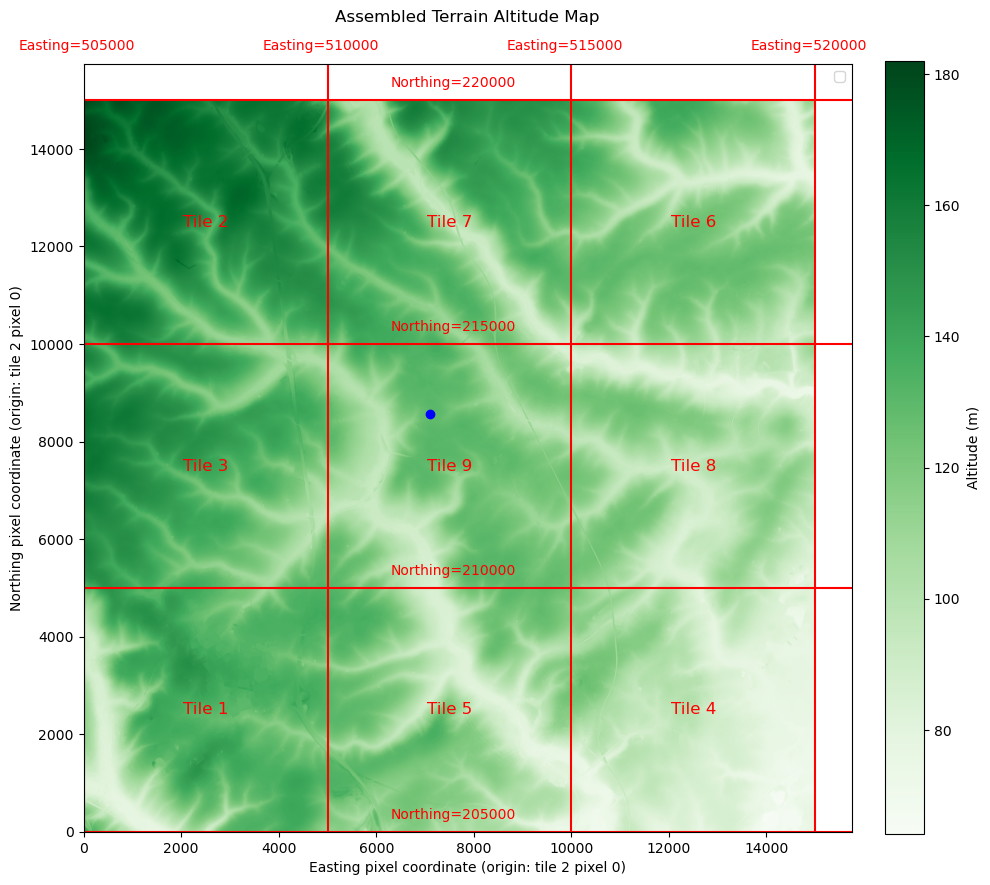

In [8]:
# Example usage, assuming coordinates_list and tiles_list are defined
assembled_image, min_x, min_y, max_x, max_y = glr.assemble_tiles(coordinates_list, tiles_list)
glr.plot_float_array_image(origin, assembled_image, min_x, min_y, max_x, max_y, coordinates_list)

## Sample the agricultural data with the gaussian distributed coordinates

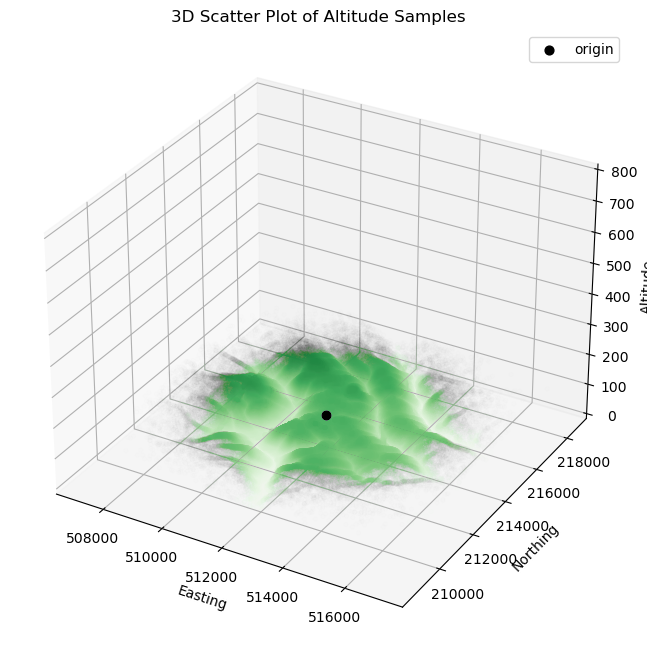

Shape:  (499652, 3)


In [9]:
ring_vertices = glr.sample_altitude(coords, origin, assembled_image, min_x, min_y)

# TODO
# Extract and associate textures for contrast as an option
# Save the ring (vertices + vt +textures if any) in a .obj file 